# EDA

In [403]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [404]:
dataset_path = "../data/raw/cs-training.csv"

df = pd.read_csv(dataset_path)
df.head()

,Unnamed: 0,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
0,1,1,0.766127,45,2,0.802982,9120.0,13,0,6,0,2.0
1,2,0,0.957151,40,0,0.121876,2600.0,4,0,0,0,1.0
2,3,0,0.658180,38,1,0.085113,3042.0,2,1,0,0,0.0
3,4,0,0.233810,30,0,0.036050,3300.0,5,0,0,0,0.0
4,5,0,0.907239,49,1,0.024926,63588.0,7,0,1,0,0.0


In [405]:
if 'Unnamed: 0' in df.columns:
    df = df.drop(columns=['Unnamed: 0'])

print(f"Total Rows: {df.shape[0]}, Total Columns: {df.shape[1]}")
df.head()

Total Rows: 150000, Total Columns: 11


,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
0,1,0.766127,45,2,0.802982,9120.0,13,0,6,0,2.0
1,0,0.957151,40,0,0.121876,2600.0,4,0,0,0,1.0
2,0,0.658180,38,1,0.085113,3042.0,2,1,0,0,0.0
3,0,0.233810,30,0,0.036050,3300.0,5,0,0,0,0.0
4,0,0.907239,49,1,0.024926,63588.0,7,0,1,0,0.0


### Target Variable Audit

In [406]:
target_counts = df["SeriousDlqin2yrs"].value_counts()
target_pct = df["SeriousDlqin2yrs"].value_counts(normalize = True) * 100

print(pd.DataFrame({"Count": target_counts, "Percentage": target_pct.round(2)}))

                   Count  Percentage
SeriousDlqin2yrs                    
0                 139974       93.32
1                  10026        6.68


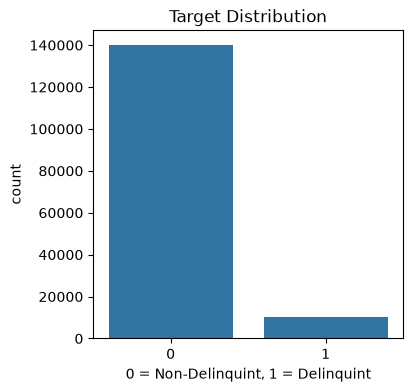

In [407]:
plt.figure(figsize = (4, 4))
sns.countplot(data = df, x = "SeriousDlqin2yrs")
plt.title("Target Distribution")
plt.xlabel("0 = Non-Delinquint, 1 = Delinquint")
plt.show()

### Missing Value Audit

In [408]:
missing_summary = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing Percentage": (df.isnull().sum()/len(df) * 100).round(2)
})

missing_summary[missing_summary["Missing Count"] > 0]

,Missing Count,Missing Percentage
MonthlyIncome,29731,19.82
NumberOfDependents,3924,2.62


In [409]:
df.groupby(df["MonthlyIncome"].isnull())["SeriousDlqin2yrs"].mean()

MonthlyIncome
False    0.069486
True     0.056137
Name: SeriousDlqin2yrs, dtype: float64

### Extreme Value and Tail Audit

In [410]:
df.describe(percentiles = [0.5, 0.75, 0.90, 0.95, 0.99, 0.999]).T[
    ["mean", "std", "min", "50%", "75%", "90%", "95%", "99%", "99.9%", "max"]
]

,mean,std,min,50%,75%,90%,95%,99%,99.9%,max
SeriousDlqin2yrs,0.066840,0.249746,0.0,0.000000,0.000000,0.000000,1.0,1.000000,1.000,1.0
RevolvingUtilizationOfUnsecuredLines,6.048438,249.755371,0.0,0.154181,0.559046,0.981278,1.0,1.092956,1571.006,50708.0
age,52.295207,14.771866,0.0,52.000000,63.000000,72.000000,78.0,87.000000,94.000,109.0
NumberOfTime30-59DaysPastDueNotWorse,0.421033,4.192781,0.0,0.000000,0.000000,1.000000,2.0,4.000000,98.000,98.0
DebtRatio,353.005076,2037.818523,0.0,0.366508,0.868254,1267.000000,2449.0,4979.040000,10613.074,329664.0
MonthlyIncome,6670.221237,14384.674215,0.0,5400.000000,8249.000000,11666.000000,14587.6,25000.000000,78395.748,3008750.0
NumberOfOpenCreditLinesAndLoans,8.452760,5.145951,0.0,8.000000,11.000000,15.000000,18.0,24.000000,34.000,58.0
NumberOfTimes90DaysLate,0.265973,4.169304,0.0,0.000000,0.000000,0.000000,1.0,3.000000,98.000,98.0
NumberRealEstateLoansOrLines,1.018240,1.129771,0.0,1.000000,2.000000,2.000000,3.0,4.000000,9.000,54.0
NumberOfTime60-89DaysPastDueNotWorse,0.240387,4.155179,0.0,0.000000,0.000000,0.000000,1.0,2.000000,98.000,98.0


### Sentinel Value Anomaly

In [411]:
delinq_cols = [
    "NumberOfTime30-59DaysPastDueNotWorse",
    "NumberOfTime60-89DaysPastDueNotWorse",
    "NumberOfTimes90DaysLate"
]

for col in delinq_cols:
    print(f"Top 5 most frequent values in {col}")
    print(f"{df[col].value_counts().head(5)}")
    print("-" * 50)

Top 5 most frequent values in NumberOfTime30-59DaysPastDueNotWorse
NumberOfTime30-59DaysPastDueNotWorse
0    126018
1     16033
2      4598
3      1754
4       747
Name: count, dtype: int64
--------------------------------------------------
Top 5 most frequent values in NumberOfTime60-89DaysPastDueNotWorse
NumberOfTime60-89DaysPastDueNotWorse
0     142396
1       5731
2       1118
3        318
98       264
Name: count, dtype: int64
--------------------------------------------------
Top 5 most frequent values in NumberOfTimes90DaysLate
NumberOfTimes90DaysLate
0    141662
1      5243
2      1555
3       667
4       291
Name: count, dtype: int64
--------------------------------------------------


#### 1. How Many Borrowers have age 0

In [412]:
print(f"Number of Borrowers with age 0: {(df["age"] == 0).sum()}")

Number of Borrowers with age 0: 1


#### 2. What Happens to DebtRatio when MonthlyIncome is 0

In [413]:
print(f"Median Debt when Monthly Income is present: {(df[df["MonthlyIncome"].notnull()]["DebtRatio"].median())}")

Median Debt when Monthly Income is present: 0.296022604


In [414]:
print(f"Median Debt when Monthly Income is not present: {(df[df["MonthlyIncome"].isnull()]["DebtRatio"].median())}")

Median Debt when Monthly Income is not present: 1159.0


#### Past Due columns containing 98 in the column

In [415]:
sentinel_98 = df[df["NumberOfTimes90DaysLate"] == 98]
print(f"Number of rows with 98 in 90-days late: {len(sentinel_98)}")
print(f"Number of rows with 98 in 60-89 days late: {len(df[df["NumberOfTime60-89DaysPastDueNotWorse"] == 98])}")
print(f"Number of rows with 98 in 90-days late: {len(df[df["NumberOfTime30-59DaysPastDueNotWorse"] == 98])}")

Number of rows with 98 in 90-days late: 264
Number of rows with 98 in 60-89 days late: 264
Number of rows with 98 in 90-days late: 264


In [416]:
print(f"Default rate of '98' cohort: {sentinel_98["SeriousDlqin2yrs"].mean().round(4)}")

Default rate of '98' cohort: 0.5417


### Default Rate vs Age Group

In [417]:
age_bins = [18, 30, 40, 50, 60, 70, 110]
age_labels = ["18 - 29", "30 - 39", "40 - 49", "50 - 59", "60 - 69", "70+"]

df["age_group"] = pd.cut(df["age"], bins = age_bins, labels = age_labels, right = False)

age_risk = df.groupby("age_group", observed = False).agg(
    total_borrowers = ("SeriousDlqin2yrs", "count"),
    default_rate = ("SeriousDlqin2yrs", "mean")
).reset_index()

age_risk["default_rate_pct"] = (age_risk["default_rate"] * 100).round(2)
print(age_risk)

  age_group  total_borrowers  default_rate  default_rate_pct
0   18 - 29             8820      0.117347             11.73
1   30 - 39            23183      0.100720             10.07
2   40 - 49            34377      0.083719              8.37
3   50 - 59            35301      0.064531              6.45
4   60 - 69            28905      0.036326              3.63
5       70+            19413      0.023180              2.32


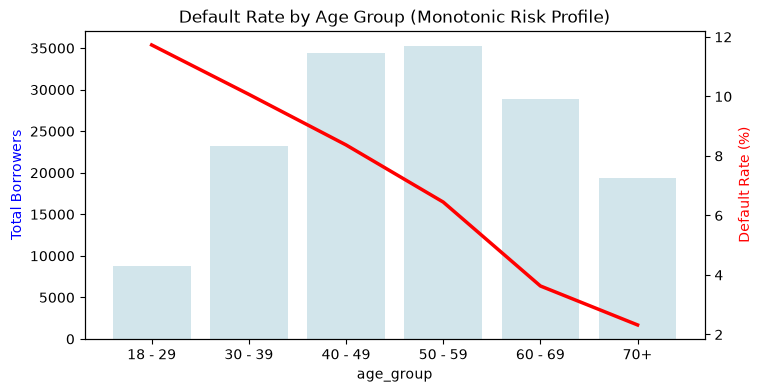

In [418]:
fig, ax1 = plt.subplots(figsize = (8, 4))
sns.barplot(data = age_risk, x = "age_group", y = "total_borrowers", color = "lightblue", alpha = 0.6, ax = ax1)

ax1.set_ylabel("Total Borrowers", color = "Blue")
ax2 = ax1.twinx()
sns.lineplot(data = age_risk, x = "age_group", y = "default_rate_pct", color = "red", markers = "o", linewidth = 2.5, ax = ax2)
ax2.set_ylabel("Default Rate (%)", color = "red")

plt.title("Default Rate by Age Group (Monotonic Risk Profile)")
plt.show()

### Default Rate vs Revolving Utilization

In [419]:
util_bins = [-np.inf, 0.1, 0.3, 0.5, 0.7, 0.9, 1.0, 1.5, np.inf]
util_labels = ["<10%", "10-30%", "30-50%", "50-70%", "70-90%", "90-100%", "100-150%", ">150%"]

df["util_bracket"] = pd.cut(df["RevolvingUtilizationOfUnsecuredLines"], bins = util_bins, labels = util_labels)

util_risk = df.groupby("util_bracket", observed = False).agg(
    total_borrowers = ("SeriousDlqin2yrs", "count"),
    default_rate = ("SeriousDlqin2yrs", "mean")
).reset_index()

util_risk["default_rate_pct"] = (util_risk["default_rate"] * 100).round(2)
print(util_risk)

  util_bracket  total_borrowers  default_rate  default_rate_pct
0         <10%            64404      0.018104              1.81
1       10-30%            28478      0.031428              3.14
2       30-50%            15830      0.058497              5.85
3       50-70%            11340      0.095679              9.57
4       70-90%             9879      0.148598             14.86
5      90-100%            16748      0.193993             19.40
6     100-150%             2721      0.397280             39.73
7        >150%              600      0.260000             26.00


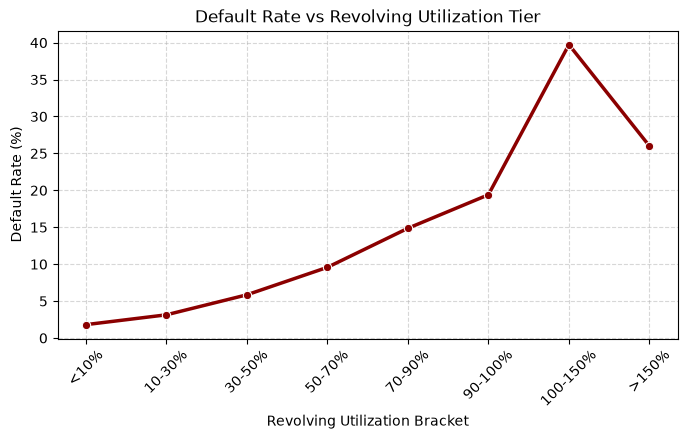

In [420]:
plt.figure(figsize = (8, 4))
sns.lineplot(data = util_risk, x = "util_bracket", y = "default_rate_pct", marker = "o", color = "darkred", linewidth = 2.5)
plt.title("Default Rate vs Revolving Utilization Tier")
plt.ylabel("Default Rate (%)")
plt.xlabel("Revolving Utilization Bracket")
plt.xticks(rotation = 45)
plt.grid(True, linestyle = "--", alpha = 0.5)
plt.show()

## Weight of Evidence(WoE) & Information Value(IV)

In [421]:
def calculate_woe(df: pd.DataFrame, feature: str, target: str, epilson: float = 1e-6) -> tuple[pd.DataFrame, float]:
    total_goods = (df[target] == 0).sum()
    total_bads = (df[target] == 1).sum()

    summary = df.groupby(feature, observed = False)[target].agg(
        total = "count",
        bads = "sum"
    ).reset_index()

    summary["goods"] = summary["total"] - summary["bads"]
    summary["bad_rate"] = (summary["bads"] / summary["total"] * 100).round(2)

    summary["percentage_good"] = summary["goods"] / total_goods
    summary["percentage_bad"] = summary["bads"] / total_bads

    summary["percentage_good"] = summary["percentage_good"].replace(0, epilson)
    summary["percentage_bad"] = summary["percentage_bad"].replace(0, epilson)

    summary["WoE"] = np.log(summary["percentage_good"] / summary["percentage_bad"])
    summary["IV"] = (summary["percentage_good"] - summary["percentage_bad"]) * summary["WoE"]

    total_iv = summary["IV"].sum()
    
    return summary, total_iv

#### Age Group

In [422]:
summary, total_iv = calculate_woe(df, "age_group", "SeriousDlqin2yrs")

print(f"Summary: \n{summary}")
print(f"\nTotal IV: {total_iv}")

Summary: 
  age_group  total  bads  goods  bad_rate  percentage_good  percentage_bad  \
0   18 - 29   8820  1035   7785     11.73         0.055617        0.103232   
1   30 - 39  23183  2335  20848     10.07         0.148942        0.232894   
2   40 - 49  34377  2878  31499      8.37         0.225035        0.287054   
3   50 - 59  35301  2278  33023      6.45         0.235922        0.227209   
4   60 - 69  28905  1050  27855      3.63         0.199001        0.104728   
5       70+  19413   450  18963      2.32         0.135475        0.044883   

        WoE        IV  
0 -0.618478  0.029448  
1 -0.447029  0.037529  
2 -0.243415  0.015096  
3  0.037631  0.000328  
4  0.641947  0.060519  
5  1.104722  0.100079  

Total IV: 0.24299920523285995


### Credit Utilization Bracket

In [423]:
summary, total_iv = calculate_woe(df, "util_bracket", "SeriousDlqin2yrs")

print(f"Summary: \n{summary}")
print(f"\nTotal IV: {total_iv}")

Summary: 
  util_bracket  total  bads  goods  bad_rate  percentage_good  percentage_bad  \
0         <10%  64404  1166  63238      1.81         0.451784        0.116298   
1       10-30%  28478   895  27583      3.14         0.197058        0.089268   
2       30-50%  15830   926  14904      5.85         0.106477        0.092360   
3       50-70%  11340  1085  10255      9.57         0.073264        0.108219   
4       70-90%   9879  1468   8411     14.86         0.060090        0.146419   
5      90-100%  16748  3249  13499     19.40         0.096439        0.324057   
6     100-150%   2721  1081   1640     39.73         0.011716        0.107820   
7        >150%    600   156    444     26.00         0.003172        0.015560   

        WoE        IV  
0  1.357051  0.455272  
1  0.791856  0.085354  
2  0.142236  0.002008  
3 -0.390090  0.013636  
4 -0.890636  0.076888  
5 -1.212007  0.275875  
6 -2.219465  0.213298  
7 -1.590306  0.019700  

Total IV: 1.1420304593724135


#### Number of Late Payments (90 Days)

In [424]:
late_90_bins = [0, 1, 2, np.inf]
late_90_labels = ["0", "1" , ">2"]

df["late_90_group"] = pd.cut(df["NumberOfTimes90DaysLate"], bins = late_90_bins, labels = late_90_labels, right = False)

late_90_risk = df.groupby("late_90_group", observed = False).agg(
    total_borrowers = ("SeriousDlqin2yrs", "count"),
    default_rate = ("SeriousDlqin2yrs", "mean")
).reset_index()

late_90_risk["default_rate_risk"] = (late_90_risk["default_rate"] * 100).round(2)
print(late_90_risk)

  late_90_group  total_borrowers  default_rate  default_rate_risk
0             0           141662      0.046265               4.63
1             1             5243      0.336639              33.66
2            >2             3095      0.551535              55.15


In [425]:
summary, total_iv = calculate_woe(df, "late_90_group", "SeriousDlqin2yrs")

print(f"Summary: \n{summary}")
print(f"\nTotal IV: {total_iv}")

Summary: 
  late_90_group   total  bads   goods  bad_rate  percentage_good  \
0             0  141662  6554  135108      4.63         0.965236   
1             1    5243  1765    3478     33.66         0.024847   
2            >2    3095  1707    1388     55.15         0.009916   

   percentage_bad       WoE        IV  
0        0.653700  0.389724  0.121413  
1        0.176042 -1.957968  0.296035  
2        0.170257 -2.843149  0.455874  

Total IV: 0.8733215595025381


#### Monthly Income

In [426]:
income_bins = [-np.inf, 2500, 5000, 7500, 10000, 15000, np.inf]
income_labels = ["0 - 2500", "2500 - 5k", "5k - 7500", "7500 - 10k", "10k - 15k", ">15k"]

df["income_bracket"] = pd.cut(df["MonthlyIncome"], bins = income_bins, labels = income_labels, right = False)
df["income_bracket"] = df["income_bracket"].cat.add_categories("Missing").fillna("Missing")

income_risk = df.groupby("income_bracket", observed = False).agg(
    total_borrowers = ("SeriousDlqin2yrs", "count"),
    default_rate = ("SeriousDlqin2yrs", "mean")
).reset_index()

income_risk["default_rate_pct"] = (income_risk["default_rate"] * 100).round(2)

print(income_risk)

  income_bracket  total_borrowers  default_rate  default_rate_pct
0       0 - 2500            16560      0.087500              8.75
1      2500 - 5k            36542      0.087598              8.76
2      5k - 7500            30363      0.064882              6.49
3     7500 - 10k            17019      0.051766              5.18
4      10k - 15k            14076      0.041986              4.20
5           >15k             5709      0.046418              4.64
6        Missing            29731      0.056137              5.61


In [427]:
summary, total_iv = calculate_woe(df, "income_bracket", "SeriousDlqin2yrs")

print(f"Summary: \n{summary}")
print(f"\nTotal IV: {total_iv}")

Summary: 
  income_bracket  total  bads  goods  bad_rate  percentage_good  \
0       0 - 2500  16560  1449  15111      8.75         0.107956   
1      2500 - 5k  36542  3201  33341      8.76         0.238194   
2      5k - 7500  30363  1970  28393      6.49         0.202845   
3     7500 - 10k  17019   881  16138      5.18         0.115293   
4      10k - 15k  14076   591  13485      4.20         0.096339   
5           >15k   5709   265   5444      4.64         0.038893   
6        Missing  29731  1669  28062      5.61         0.200480   

   percentage_bad       WoE        IV  
0        0.144524 -0.291726  0.010668  
1        0.319270 -0.292950  0.023751  
2        0.196489  0.031834  0.000202  
3        0.087872  0.271599  0.007448  
4        0.058947  0.491242  0.018369  
5        0.026431  0.386265  0.004813  
6        0.166467  0.185917  0.006324  

Total IV: 0.07157492684469235
